# Sentinel · Explanations, calibration and drift

A reproducible experiment using the same application modules as the running project. Run all cells in order. Demonstration data and fixed corpora are not evidence of production performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Train using the documented split

Recreate the same three fitted models and select the winner on validation average precision. Subsequent test diagnostics must not be used to select a different winner.

In [2]:
from app.services.model import dataset,splits,train_models,metrics
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
x,y=dataset();xt,xv,xe,yt,yv,ye=splits(x,y)
bundle=train_models(x,y);name=bundle['winner'];model=bundle['models'][name]
p=model.predict_proba(xe)[:,1]
display(pd.DataFrame(bundle['metrics']).T.drop(columns='confusion_matrix').round(4))
print('Frozen model selection:',name)

Frozen model selection: XGBoost


,precision,recall,f1,roc_auc,average_precision,false_positive_rate,threshold
Logistic Regression,0.162162,0.176471,0.169014,0.758929,0.103771,0.026587,0.84036
Random Forest,0.173913,0.235294,0.2,0.784129,0.150056,0.03259,0.399553
XGBoost,0.139535,0.176471,0.155844,0.804081,0.151824,0.031732,0.150697


## Probability calibration diagnostic

A well-ranked classifier need not produce calibrated probabilities. Display reliability curves and Brier scores; do not recalibrate on the test set.

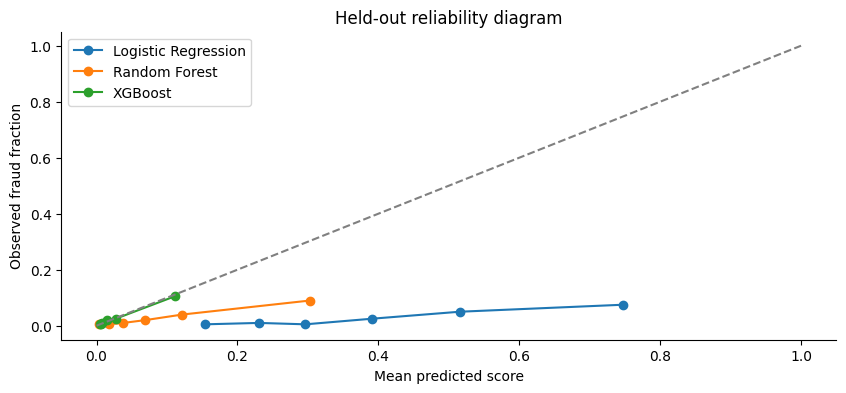

,model,brier,mean_score,observed_rate
0,Logistic Regression,0.1877,0.3892,0.0283
1,Random Forest,0.0366,0.0923,0.0283
2,XGBoost,0.0263,0.0286,0.0283


In [3]:
fig,ax=plt.subplots()
calibration_rows=[]
for label,clf in bundle['models'].items():
    probabilities=clf.predict_proba(xe)[:,1]
    fraction,mean=calibration_curve(ye,probabilities,n_bins=6,strategy='quantile')
    ax.plot(mean,fraction,marker='o',label=label)
    calibration_rows.append({'model':label,'brier':brier_score_loss(ye,probabilities),
                             'mean_score':probabilities.mean(),'observed_rate':ye.mean()})
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Mean predicted score',ylabel='Observed fraud fraction',title='Held-out reliability diagram');ax.legend();plt.show()
display(pd.DataFrame(calibration_rows).round(4))

## Permutation importance

Measure the reduction in held-out average precision after permuting each feature. Negative effects are possible on a small noisy test sample. This is a diagnostic, not a causal estimate.

,feature,mean_ap_drop,std_ap_drop
5,international,0.0056,0.0209
4,account_age_days,0.0174,0.0074
2,distance_km,0.0459,0.0217
0,amount,0.0496,0.0197
3,transactions_24h,0.0513,0.0254
1,hour,0.0574,0.0092


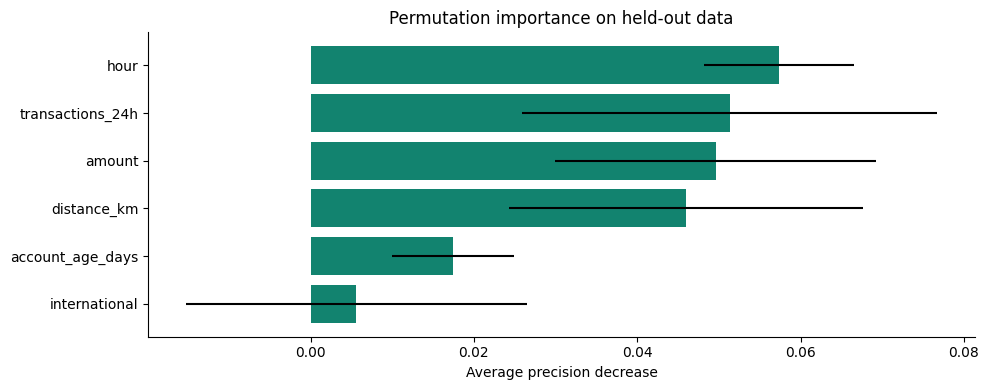

In [4]:
from sklearn.inspection import permutation_importance
importance=permutation_importance(model,xe,ye,scoring='average_precision',n_repeats=5,random_state=42,n_jobs=1)
importance_table=pd.DataFrame({'feature':xe.columns,'mean_ap_drop':importance.importances_mean,'std_ap_drop':importance.importances_std}).sort_values('mean_ap_drop')
display(importance_table.round(4))
plt.barh(importance_table.feature,importance_table.mean_ap_drop,xerr=importance_table.std_ap_drop,color='#12836f');plt.xlabel('Average precision decrease');plt.title('Permutation importance on held-out data');plt.tight_layout();plt.show()

## Verify additive SHAP explanations

Use the random forest probability-space explanation and verify that its base value plus contributions reconstructs the positive-class prediction.

,model_probability,shap_reconstruction,absolute_error
0,0.034861,3.486098e-02,1.174061e-14
1,0.056591,5.659092e-02,1.122713e-14
2,0.023157,2.315689e-02,1.225756e-14
3,0.000000,1.187939e-14,1.187939e-14
4,0.194743,1.947428e-01,1.182388e-14


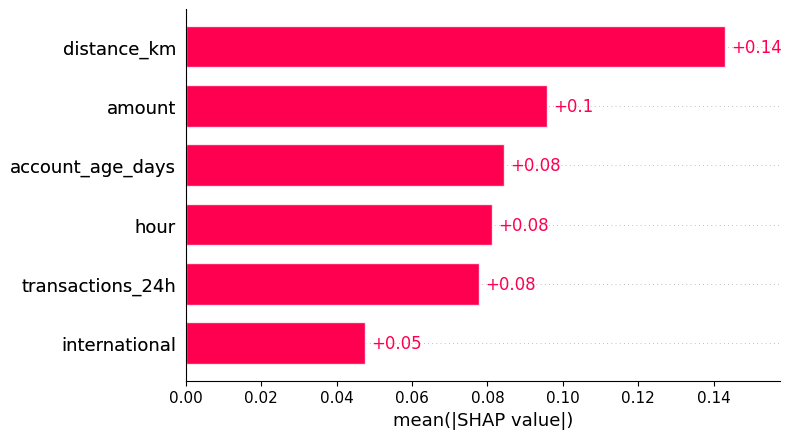

In [5]:
import shap
forest=bundle['models']['Random Forest'];sample=xe.iloc[:20]
explanations=shap.TreeExplainer(forest)(sample)
positive=explanations[:,:,1] if explanations.values.ndim==3 else explanations
reconstructed=np.asarray(positive.base_values)+positive.values.sum(axis=1)
actual=forest.predict_proba(sample)[:,1]
np.testing.assert_allclose(reconstructed,actual,atol=1e-6)
display(pd.DataFrame({'model_probability':actual,'shap_reconstruction':reconstructed,'absolute_error':abs(actual-reconstructed)}).head())
shap.plots.bar(positive,show=False);plt.tight_layout();plt.show()

## Covariate shift stress test

Shift amount and distance while keeping the other features fixed. Labels under the shifted population are unknown, so compare score distributions rather than claiming a measured accuracy loss.

{'baseline_mean_score': 0.028594141826033592,
 'shifted_mean_score': 0.1267518252134323,
 'ks_statistic': 0.625,
 'population_stability_index': 3.6113428736127893}

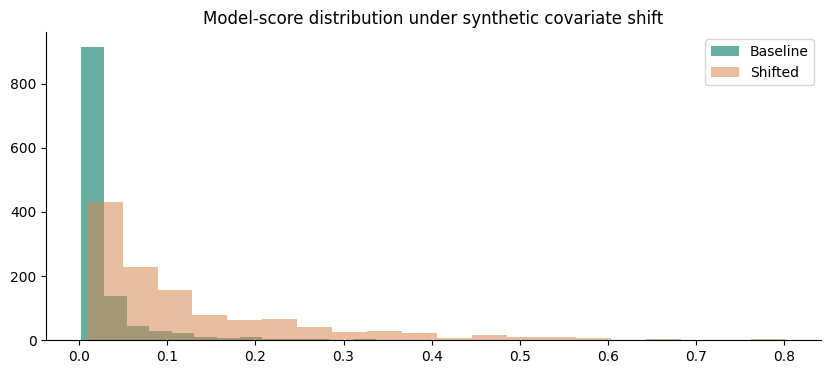

In [6]:
from scipy.stats import ks_2samp
shifted=xe.copy();shifted['amount']=(shifted.amount*3).clip(upper=1000000);shifted['distance_km']=(shifted.distance_km+250).clip(upper=20000)
shifted_scores=model.predict_proba(shifted)[:,1]
ks=ks_2samp(p,shifted_scores)
bins=np.unique(np.quantile(p,np.linspace(0,1,11)));bins[0]=-np.inf;bins[-1]=np.inf
baseline=np.histogram(p,bins)[0]+.5;changed=np.histogram(shifted_scores,bins)[0]+.5
baseline=baseline/baseline.sum();changed=changed/changed.sum()
psi=float(np.sum((changed-baseline)*np.log(changed/baseline)))
display({'baseline_mean_score':float(p.mean()),'shifted_mean_score':float(shifted_scores.mean()),'ks_statistic':float(ks.statistic),'population_stability_index':psi})
plt.hist(p,bins=20,alpha=.65,label='Baseline',color='#12836f');plt.hist(shifted_scores,bins=20,alpha=.55,label='Shifted',color='#d78753');plt.legend();plt.title('Model-score distribution under synthetic covariate shift');plt.show()

## Segment errors and operational limits

Report support and class prevalence alongside segment precision and recall. International status is a model feature, not a protected-class audit. Small subgroup counts make comparisons unstable.

In [7]:
rows=[];threshold=bundle['thresholds'][name]
for international in [0,1]:
    mask=xe.international==international
    result=metrics(ye[mask],p[mask],threshold)
    rows.append({'international':international,'samples':int(mask.sum()),'fraud_cases':int(ye[mask].sum()),
                 'precision':result['precision'],'recall':result['recall'],'false_positive_rate':result['false_positive_rate']})
display(pd.DataFrame(rows).round(4))
print('Before deployment: obtain real labelled data, temporal/entity splits, calibration and a review-cost model. These synthetic diagnostics do not establish fairness or safety.')

Before deployment: obtain real labelled data, temporal/entity splits, calibration and a review-cost model. These synthetic diagnostics do not establish fairness or safety.


,international,samples,fraud_cases,precision,recall,false_positive_rate
0,0,1069,27,0.1538,0.1481,0.0211
1,1,131,7,0.1176,0.2857,0.1210
